<a href="https://colab.research.google.com/github/tesfalemhabtamu2-web/Straight-of-hormuz-conflict-impact-analysis./blob/main/01_brent_oil_price_analysis_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Our research project has started!

First five observations:
        date  brent_price
0 2025-01-02        76.14
1 2025-01-03        76.72
2 2025-01-06        77.27
3 2025-01-07        77.84
4 2025-01-08        77.37

Last five observations:
          date  brent_price
464 2026-10-14       126.55
465 2026-10-15       126.35
466 2026-10-16       119.33
467 2026-10-19       118.82
468 2026-10-20       115.22

Number of observations: 456
First date: 2025-01-02
Last date: 2026-10-20


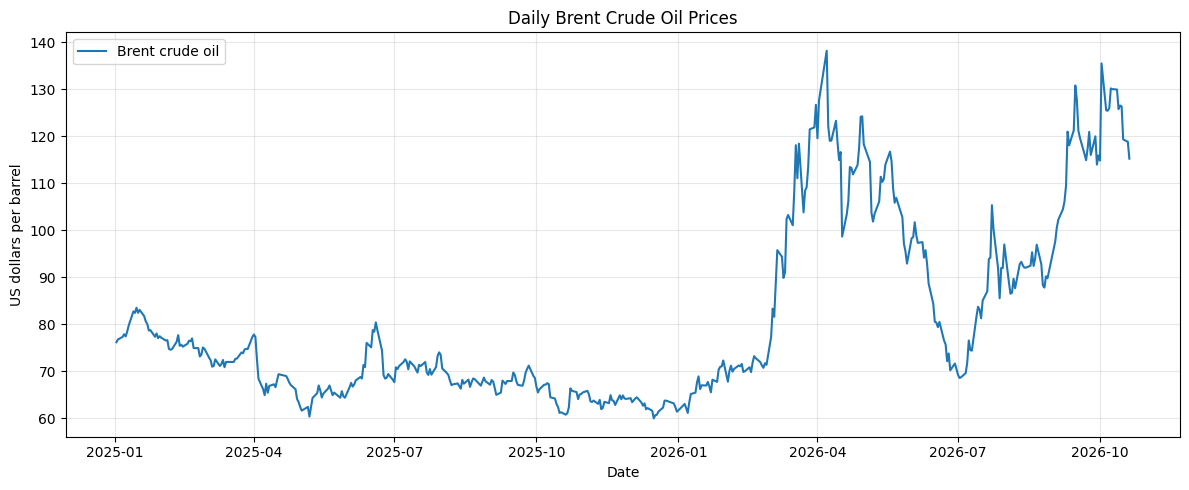

In [ ]:


# STEP 1: Import the tools we need

import pandas as pd
import matplotlib.pyplot as plt

print("Our research project has started!")

# STEP 2: Download Brent crude oil price data from FRED

url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    "?id=DCOILBRENTEU"
    "&cosd=2025-01-01"
)

df = pd.read_csv(url)

# STEP 3: Clean the column names

df.columns = ["date", "brent_price"]

df["date"] = pd.to_datetime(df["date"])
df["brent_price"] = pd.to_numeric(
    df["brent_price"], errors="coerce"
)

df = df.dropna().sort_values("date")

# STEP 4: Display the data

print("\nFirst five observations:")
print(df.head())

print("\nLast five observations:")
print(df.tail())

print("\nNumber of observations:", len(df))
print("First date:", df["date"].min().date())
print("Last date:", df["date"].max().date())

# STEP 5: Create our first chart

plt.figure(figsize=(12, 5))

plt.plot(
    df["date"],
    df["brent_price"],
    label="Brent crude oil"
)

plt.title("Daily Brent Crude Oil Prices")
plt.xlabel("Date")
plt.ylabel("US dollars per barrel")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Observations before: 43
Observations after: 41

RESULTS
Average price before: $ 68.37
Average price after:  $ 109.52
Difference per barrel: $ 41.15
Percentage difference: 60.19 %


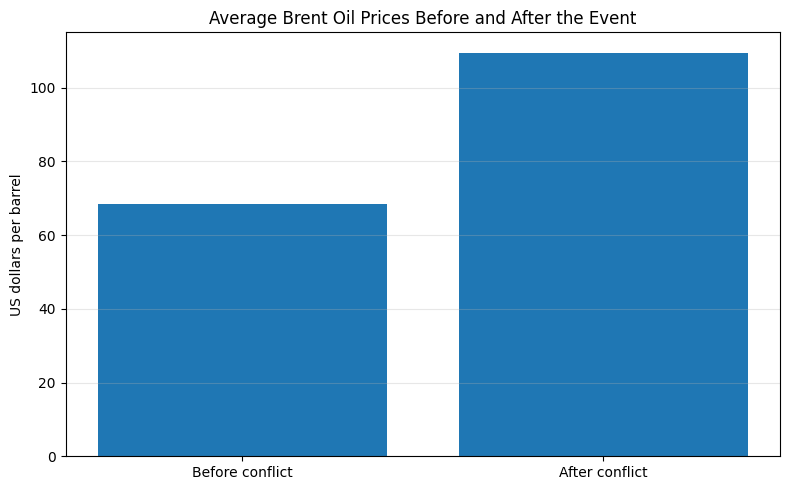

In [3]:


# STEP 3: Compare oil prices before and after the event

import pandas as pd
import matplotlib.pyplot as plt

# Define the event date
event_date = pd.Timestamp("2026-02-28")

# Select 60 calendar days before the event
before = df[
    (df["date"] >= event_date - pd.Timedelta(days=60))
    & (df["date"] < event_date)
]

# Select 60 calendar days after the event
after = df[
    (df["date"] > event_date)
    & (df["date"] <= event_date + pd.Timedelta(days=60))
]

# Calculate average prices
before_average = before["brent_price"].mean()
after_average = after["brent_price"].mean()

print("Observations before:", len(before))
print("Observations after:", len(after))

if pd.notna(before_average) and pd.notna(after_average):
    difference = after_average - before_average
    percentage_change = difference / before_average * 100

    print("\nRESULTS")
    print("Average price before: $", round(before_average, 2))
    print("Average price after:  $", round(after_average, 2))
    print("Difference per barrel: $", round(difference, 2))
    print("Percentage difference:", round(percentage_change, 2), "%")
else:
    print("Insufficient data for the comparison.")

# Plot the comparison
plt.figure(figsize=(8, 5))

plt.bar(
    ["Before conflict", "After conflict"],
    [before_average, after_average]
)

plt.title("Average Brent Oil Prices Before and After the Event")
plt.ylabel("US dollars per barrel")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:


# STEP 4: Check the reliability of our results

def summarize_period(data, period_name):
    print(f"\n{period_name}")
    print("-" * 35)
    print("Trading-day observations:", len(data))
    print("Average price:", round(data["brent_price"].mean(), 2))
    print("Median price:", round(data["brent_price"].median(), 2))
    print("Minimum price:", round(data["brent_price"].min(), 2))
    print("Maximum price:", round(data["brent_price"].max(), 2))
    print("Standard deviation:", round(data["brent_price"].std(), 2))

summarize_period(before, "BEFORE THE EVENT")
summarize_period(after, "AFTER THE EVENT")

# Save a research summary
summary = pd.DataFrame({
    "period": ["Before event", "After event"],
    "observations": [len(before), len(after)],
    "average_price": [
        before["brent_price"].mean(),
        after["brent_price"].mean()
    ],
    "median_price": [
        before["brent_price"].median(),
        after["brent_price"].median()
    ],
    "minimum_price": [
        before["brent_price"].min(),
        after["brent_price"].min()
    ],
    "maximum_price": [
        before["brent_price"].max(),
        after["brent_price"].max()
    ]
})

summary.to_csv("oil_price_summary.csv", index=False)

print("\nSummary saved as oil_price_summary.csv")


BEFORE THE EVENT
-----------------------------------
Trading-day observations: 43
Average price: 68.37
Median price: 69.8
Minimum price: 61.08
Maximum price: 73.17
Standard deviation: 3.45

AFTER THE EVENT
-----------------------------------
Trading-day observations: 41
Average price: 109.52
Median price: 113.25
Minimum price: 77.24
Maximum price: 138.21
Standard deviation: 13.7

Summary saved as oil_price_summary.csv
